In [2]:
from pathlib import Path
import cv2
import matplotlib.pyplot as plt

### load images 

In [3]:
DATASET_DIR = Path("data")

train_dir = DATASET_DIR / "train"
valid_dir = DATASET_DIR / "valid"
test_dir = DATASET_DIR / "test"


print("Train exists:", train_dir.exists())
print("Valid exists:", valid_dir.exists())
print("Test exists:", test_dir.exists())

Train exists: True
Valid exists: True
Test exists: True


In [4]:
train_images = list(train_dir.rglob("*.jpg"))

print("Number of training images:", len(train_images))

Number of training images: 77


In [5]:
egg_images = list((train_dir / "egg").rglob("*.jpg"))
unlabeled_images = list((train_dir / "Unlabeled").rglob("*.jpg"))

print("Labeled egg images:", len(egg_images))
print("Unlabeled images:", len(unlabeled_images))

Labeled egg images: 75
Unlabeled images: 2


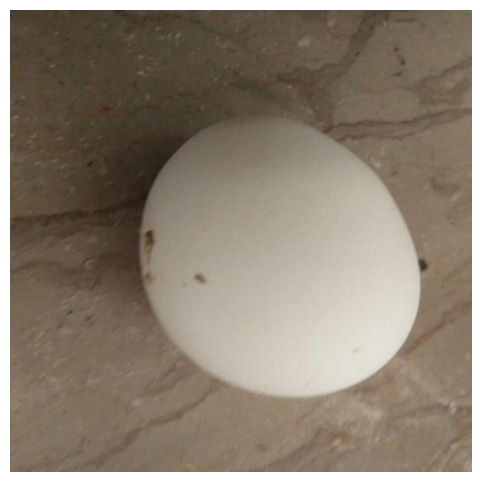

In [6]:
img = cv2.imread(str(egg_images[0]))
img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

plt.figure(figsize=(8, 6))
plt.imshow(img)
plt.axis("off");

In [7]:
print((DATASET_DIR / "README.roboflow.txt").read_text())


egg - v1 2025-05-23 2:44pm

This dataset was exported via roboflow.com on May 23, 2025 at 6:46 AM GMT

Roboflow is an end-to-end computer vision platform that helps you
* collaborate with your team on computer vision projects
* collect & organize images
* understand and search unstructured image data
* annotate, and create datasets
* export, train, and deploy computer vision models
* use active learning to improve your dataset over time

For state of the art Computer Vision training notebooks you can use with this dataset,
visit https://github.com/roboflow/notebooks

To find over 100k other datasets and pre-trained models, visit https://universe.roboflow.com

The dataset includes 110 images.
Egg are annotated in folder format.

The following pre-processing was applied to each image:
* Auto-orientation of pixel data (with EXIF-orientation stripping)
* Resize to 640x640 (Stretch)

No image augmentation techniques were applied.





### Inspect image

Image shape (height, width, channels): (640, 640, 3)


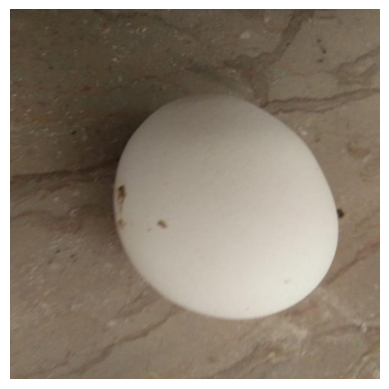

In [8]:
img = cv2.imread(str(egg_images[0]))

print("Image shape (height, width, channels):", img.shape)

plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
plt.axis("off");

In [9]:
for split in ["train", "valid", "test"]:
    egg_folder = DATASET_DIR / split / "egg"
    images = list(egg_folder.glob("*.jpg"))
    print(f"{split}: {len(images)} images")

train: 75 images
valid: 22 images
test: 11 images


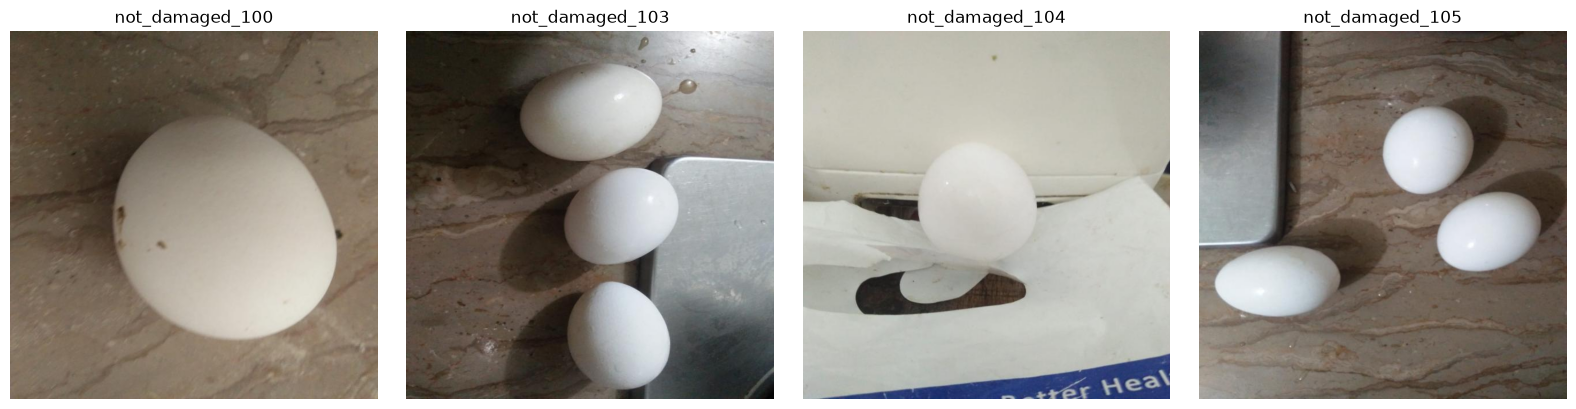

In [10]:
fig, axes = plt.subplots(1, 4, figsize=(16, 4))

for ax, path in zip(axes, egg_images[:4]):
    img = cv2.imread(str(path))
    img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    ax.imshow(img)
    ax.set_title(path.name[:15])
    ax.axis("off")

plt.tight_layout()

### Understand pixel values

In [12]:
img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

print("Minimum pixel value:", img_rgb.min())
print("Maximum pixel value:", img_rgb.max())
print("Mean RGB values:", img_rgb.mean(axis=(0, 1)))

Minimum pixel value: 4
Maximum pixel value: 230
Mean RGB values: [130.47625488 117.43789551 101.49178223]
